# Lesson 06 · Beta-binomial regression

**Source:** *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 7 (pp. 56–64)

**Question:** Better hitters get more at-bats. If we shrink everyone toward one global average, are we systematically overrating players with short careers?

**Goal:** Rewrite the beta prior in terms of a mean μ and a dispersion σ, let μ depend on log(AB), fit it by maximum likelihood, and shrink each player toward his own prior.

**Contents**

1. Setup
2. The problem: AB and average are related
3. Reparameterizing the beta: μ and σ
4. The model and its likelihood
5. Fit it (step 1)
6. Shrink toward the trend (step 2)
7. Exercises

**Tags:** `beta-binomial-regression` `confounding` `reparameterization` `maximum-likelihood` `shrinkage` `prior-depends-on-covariates`

**Before you start:** Lessons 02 and 05. This lesson writes a general fitting function you'll reuse in Lessons 07 and 10.

*How this notebook works:* each **Your turn** prompt is followed by an empty cell for your code. **Check** boxes give values to compare against; they come from the book, and your numbers can differ slightly because the Lahman data now runs through more recent seasons. **Reflect** prompts are for short written answers. Every prompt is numbered *lesson.section.question* (for example **2.3.1**), so you can refer to it; empty code cells and answer cells carry the same number.

In [1]:
# --- Setup: run this cell first ------------------------------------------
# Windows + conda: put the environment's DLL folders on PATH, so plotting
# can't crash the kernel when Jupyter wasn't started from the activated env.
import os, sys
for sub in ["Library\\mingw-w64\\bin", "Library\\usr\\bin", "Library\\bin", "Scripts", "bin"]:
    p = os.path.join(sys.prefix, sub)
    if os.path.isdir(p) and p not in os.environ["PATH"]:
        os.environ["PATH"] = p + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats, optimize, special

import eb_data   # helpers in this folder: loading the Lahman data, saving results

rng = np.random.default_rng(2017)
pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (7, 4)
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

career = eb_data.career(pitcher_rule=3)
alpha0, beta0 = eb_data.load_prior()
print(f"{len(career):,} players | prior alpha0 = {alpha0:.1f}, beta0 = {beta0:.1f}")

numpy 2.5.3 | pandas 3.0.6 | scipy 1.18.1
13,446 players | prior alpha0 = 95.3, beta0 = 271.5


## 1. Setup

**6.1.1 · Your turn.** Add `eb_estimate`, `alpha1` and `beta1` using the single prior, as before.

In [2]:
# 6.1.1 · Your code here

career['alpha1'] = alpha0 + career.H
career['beta1'] = beta0 + career.AB - career.H
career['eb_estimate'] = (career.alpha1 / (career.alpha1 + career.beta1))

career.head()

,playerID,name,H,AB,average,alpha1,beta1,eb_estimate
0,aaronha01,Hank Aaron,3771,12364,0.3050,3866.3306,8864.4864,0.3037
1,aaronto01,Tommie Aaron,216,944,0.2288,311.3306,999.4864,0.2375
2,abadan01,Andy Abad,2,21,0.0952,97.3306,290.4864,0.2510
3,abadijo01,John Abadie,11,49,0.2245,106.3306,309.4864,0.2557
4,abbated01,Ed Abbaticchio,772,3044,0.2536,867.3306,2543.4864,0.2543


## 2. The problem: AB and average are related

**6.2.1 · Your turn.** Plot raw `average` against `AB` (log x-axis) for players with AB ≥ 10. Add a smooth trend: a binned median, or `np.polyfit` on log AB.

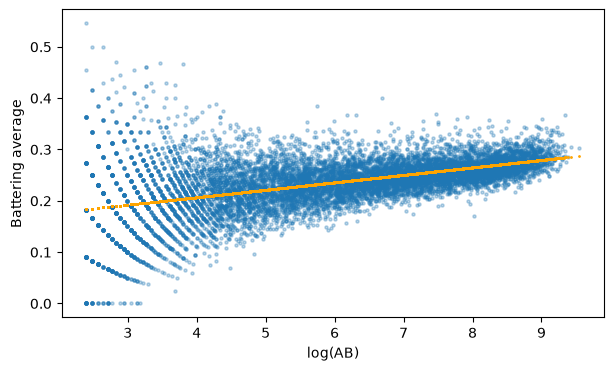

In [3]:
# 6.2.1 · Your code here
career10 = career[career.AB > 10]
plt.scatter(np.log(career10.AB), career10.average, alpha = 0.3, s = 5)
fit = np.polyfit(np.log(career10.AB), career10.average, deg = 1)
plt.scatter(np.log(career10.AB), ((fit[0] * np.log(career10.AB)) + fit[1]), color = 'orange', s=1)
plt.xlabel("log(AB)")
plt.ylabel("Battering average")
plt.show()

**6.2.2 · Your turn.** What's the median raw average for players with 5–20 AB? What does single-prior shrinkage turn them into? Plot `eb_estimate` against AB with the prior mean as a horizontal line.

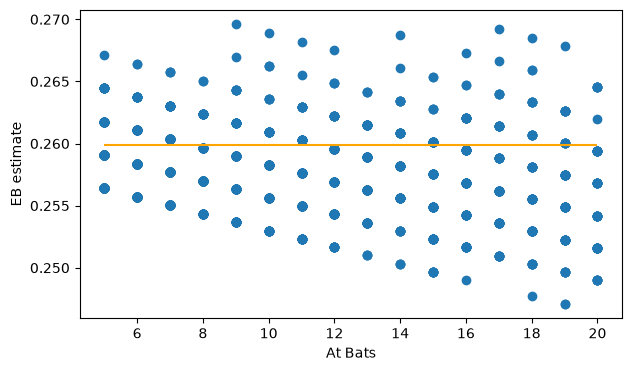

In [4]:
# 6.2.2 · Your code here

career_lowAB = career[(career.AB <= 20) & (career.AB >= 5)]
median_lowAB = np.median(career_lowAB.average)
plt.scatter(career_lowAB.AB, career_lowAB.eb_estimate)
plt.hlines(y=((alpha0)/(alpha0 + beta0)), xmin = 5, xmax = 20, color = 'orange')
#plt.hlines(y=median_lowAB, xmin = 5, xmax = 20, color = 'green')
plt.xlabel("At Bats")
plt.ylabel("EB estimate")
plt.show()

> **Check:** the median raw average for 5–20 AB is about 0.167, far below the prior mean of about 0.26.

**6.2.3 · Reflect.** This relationship isn't measurement noise: why does it exist? In which direction does it bias the single-prior estimates, and for which players?

*6.2.3 · Your answer:*

This is due to an underlying relationship between a player's ABs and their batting average, that better batters go up to hit more. Our previous models drew batting average priors from a single beta distribution, not accounting for this relationship. It greatly overestimates the true batting average of low AB players.

## 3. Reparameterizing the beta: μ and σ

Write the beta in terms of its mean $\mu$ and a dispersion $\sigma$:

$$\mu = \frac{\alpha}{\alpha+\beta}, \quad \sigma = \frac{1}{\alpha+\beta} \qquad\Longleftrightarrow\qquad \alpha = \frac{\mu}{\sigma}, \quad \beta = \frac{1-\mu}{\sigma}.$$

Small $\sigma$ means a tight, informative prior.

**6.3.1 · Your turn.** Write `to_mu_sigma(alpha, beta)` and `to_alpha_beta(mu, sigma)`. Convert your α₀, β₀ and back.

In [5]:
# 6.3.1 · Your code here

def to_mu_sigma(alpha, beta):
    mu = (alpha / (alpha + beta))
    sigma = (1 / (alpha + beta))
    return mu, sigma

def to_alpha_beta(mu, sigma):
    alpha = mu / sigma
    beta = ((1 - mu) / sigma)
    return alpha, beta
m0, s0 = to_mu_sigma(alpha0, beta0)
print(m0, s0)
print(to_alpha_beta(m0, s0))

0.25988593373266905 0.0027261553008034664
(95.33056816538446, 271.48639186080146)


## 4. The model and its likelihood

Now let the prior mean depend on at-bats:

$$\mu_i = \mu_0 + \mu_{AB}\,\log(AB_i), \qquad p_i \sim \text{Beta}\!\left(\frac{\mu_i}{\sigma_0}, \frac{1-\mu_i}{\sigma_0}\right), \qquad H_i \sim \text{Binomial}(AB_i, p_i).$$

This is **beta-binomial regression**. The book fits it with R's `gamlss`. We'll write the likelihood ourselves. Write it generally, with a design matrix `X` (a column of ones plus predictors) and coefficients `b`, so that $\mu = Xb$. Then Lesson 07 can add predictors without new code.

**6.4.1 · Your turn.** Write `bb_reg_neg_log_lik(params, H, AB, X)`, where `params = [*b, log_sigma]`:
- `mu = X @ b`, clipped to (1e-6, 1 − 1e-6) so that bad steps don't crash the optimizer;
- `alpha = mu / sigma`, `beta = (1 - mu) / sigma`;
- return `-stats.betabinom.logpmf(H, AB, alpha, beta).sum()`.

In [6]:
# 6.4.1 · Your code here
X = np.column_stack((np.full(len(career), 1), np.log(career.AB)))

def bb_reg_neg_log_lik(params, H, AB, X):
    '''
    Parameters
    ----------
    params : array, length n + 1
        [*b, log_sigma]: n regression coefficients, then log of the dispersion sigma.
    
    H, AB : arrays, length m
        Observed Hits H and At-bats AB for a list of m players
        
    X : array, shape (m, n)
        A design matrix of m players with n parameters. For this function, the first column is 1's, and the second is log(AB)

    Performs X @ b (where b is the n x 1 matrix of parameter values) to generate a m x 1 array of central values 
    'mu' for the list of m players. The dispersion 'sigma' is calculated as e^(log_sigma), and is assumed to be 
    the same across players.

    Re-parameterizes mu and sigma values into alpha and beta parameters for a beta distribution.

    Evaluates binomial distribution for H hits in AB at-bats, averaging over all batting averages generated by the beta distributions,
    for every player.
    
    Returns negative sum of log likelihood for all players, a measure of how well the n params explain the observed data assuming
    a binomial distribution H ~ Binom(AB, p) of H hits and AB at bats drawn from a beta distribution of p where p ~ Beta(alpha, beta)
    where alpha and beta are converted from mu and sigma, which take into account a linear relationship between p and logAB.
    '''
    [*b, log_sigma] = params
    mu = np.clip((X @ b), 1e-6, (1-1e-6))
    sigma = np.exp(log_sigma)
    alpha = mu / sigma
    beta = ((1 - mu)/sigma)
    return -stats.betabinom.logpmf(H, AB, alpha, beta).sum()

## 5. Fit it (step 1)

**6.5.1 · Your turn.** Write `fit_bb_regression(H, AB, X, start=None)` that calls `optimize.minimize` and returns the coefficients, σ, and (optionally) standard errors from the inverse Hessian. Fit it with `X = [1, log(AB)]` on all players.

Good starting values help: the intercept near 0.15, slope near 0.01, `log_sigma` near −6. Try `method="L-BFGS-B"`, and `"Nelder-Mead"` if it struggles.

In [7]:
# 6.5.1 · Your code here
def fit_bb_regression(H, AB, X, start = None):
    if start is None:
        start = [0.15, 0.01, -6]
    res = optimize.minimize(bb_reg_neg_log_lik, x0 = start, args = (H, AB, X), method = "L-BFGS-B")
    coeffs = res.x[:-1]
    sigfit = res.x[-1]
    return *coeffs, np.exp(sigfit)

mu0_fit, muAB_fit, sig_fit = fit_bb_regression(career.H, career.AB, X)
print(mu0_fit, muAB_fit, sig_fit)

0.14842999322124256 0.014528019575642842 0.0021850478502553807


> **Check:** μ₀ ≈ 0.143, μ_AB ≈ 0.0153, σ₀ ≈ exp(−6.29) ≈ 0.0019.

**6.5.2 · Your turn.** Plot the prior density implied for players with AB = 1, 10, 100, 1,000 and 10,000.

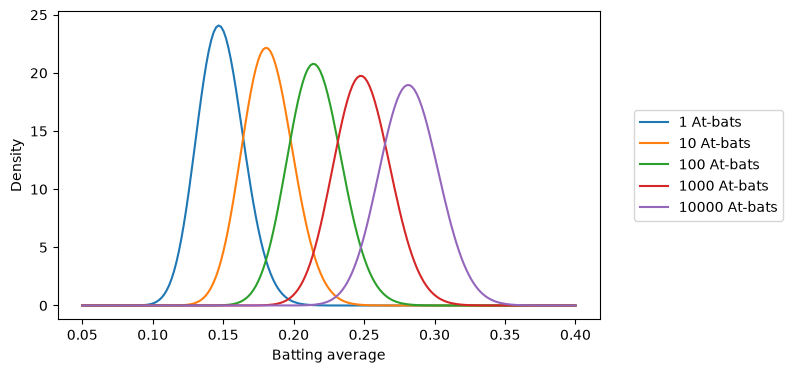

In [8]:
# 6.5.2 · Your code here

ABs = [1, 10, 100, 1000, 10000]

for atbats in ABs: 
    x = np.linspace(0.05, 0.4, 200)
    mui = mu0_fit + (muAB_fit * np.log(atbats))
    alpha, beta = to_alpha_beta(mui, sig_fit)
    plt.plot(x, stats.beta(alpha,beta).pdf(x), label = f"{atbats} At-bats")
plt.xlabel('Batting average')
plt.ylabel('Density')
plt.legend(bbox_to_anchor=(1.05, 0.5), loc="center left")
plt.show() 

## 6. Shrink toward the trend (step 2)

**6.6.1 · Your turn.** Give each player his own prior (`alpha0_i`, `beta0_i` from his μᵢ), update with H and AB, and store `new_eb`.

In [9]:
# 6.6.1 · Your code here
career['alpha0_i'], career['beta0_i'] = to_alpha_beta(mu0_fit + (muAB_fit * np.log(career.AB)), sig_fit)
career['alpha1_i'] = career.alpha0_i + career.H
career['beta1_i'] = career.beta0_i + career.AB - career.H
career['new_eb']  = career.alpha1_i / (career.alpha1_i + career.beta1_i)
career.head()

,playerID,name,H,AB,average,alpha1,beta1,eb_estimate,alpha0_i,beta0_i,alpha1_i,beta1_i,new_eb
0,aaronha01,Hank Aaron,3771,12364,0.3050,3866.3306,8864.4864,0.3037,130.5788,327.0771,3901.5788,8920.0771,0.3043
1,aaronto01,Tommie Aaron,216,944,0.2288,311.3306,999.4864,0.2375,113.4752,344.1807,329.4752,1072.1807,0.2351
2,abadan01,Andy Abad,2,21,0.0952,97.3306,290.4864,0.2510,88.1724,369.4835,90.1724,388.4835,0.1884
3,abadijo01,John Abadie,11,49,0.2245,106.3306,309.4864,0.2557,93.8059,363.8500,104.8059,401.8500,0.2069
4,abbated01,Ed Abbaticchio,772,3044,0.2536,867.3306,2543.4864,0.2543,121.2597,336.3962,893.2597,2608.3962,0.2551


**6.6.2 · Your turn.** Compare `eb_estimate` with `new_eb`: scatter one against the other, and plot both against AB (log x) with the fitted trend line.

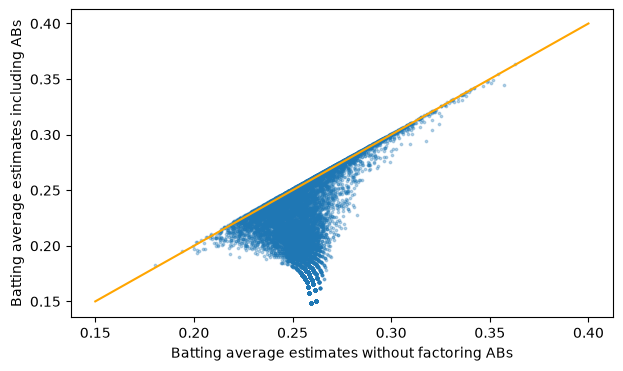

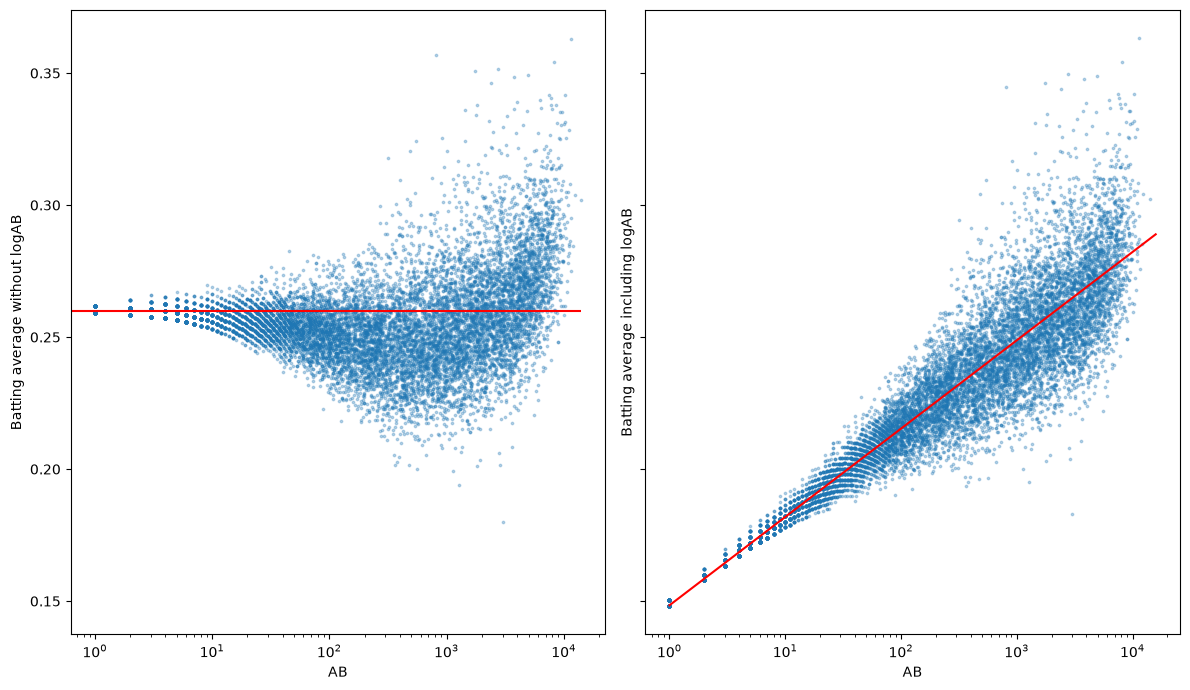

In [18]:
# 6.6.2 · Your code here
xs = np.linspace(0.15, 0.4, 200)
ys = xs
plt.scatter(career.eb_estimate, career.new_eb, s=3, alpha=0.3)
plt.plot(xs, ys, ls = '-', color = 'orange')
plt.xlabel('Batting average estimates without factoring ABs')
plt.ylabel('Batting average estimates including ABs')
plt.show() 

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey = True)  

axes[0].scatter(career.AB, career.eb_estimate, s=3, alpha=0.3)
axes[0].hlines((alpha0 / (alpha0 + beta0)), xmin = 0, xmax = career.AB.max(), color = 'red') 
axes[0].set_xscale('log')
axes[0].set_xlabel('AB')
axes[0].set_ylabel('Batting average without logAB')

axes[1].scatter(career.AB, career.new_eb, s=3, alpha=0.3)
xs = np.logspace(0, 4.2, 200)
axes[1].plot(xs, mu0_fit + (muAB_fit * np.log(xs)), color = 'red')
axes[1].set_xscale('log')
axes[1].set_xlabel('AB')
axes[1].set_ylabel('Batting average including logAB')

plt.tight_layout()   # stops titles and labels from overlapping
plt.show()

**6.6.3 · Reflect.** The book points out that AB is only known at the *end* of a career. What does that mean for using this model on a rookie? Which later results (credible intervals, PEPs, A/B tests) change with the new prior?

*6.6.3 · Your answer:*

On a rookie, in which AB is low, this model would behave similarly to our previous one where we did not take AB into account at all. It would overestimate the posterior batting average for low AB players, and therefore affect everything that depended on those posteriors, including credible intervals, PEPs, and our A/B testing.

**6.6.4 · Your turn.** Save your coefficients: `eb_data.save_result("bb_reg_logAB", {...})`.

In [19]:
# 6.6.4 · Your code here
eb_data.save_result("bb_reg_logAB", 
                    {
                    "mu0_fit" : mu0_fit,
                    "muAB_fit" : muAB_fit,
                    "sig_fit" : sig_fit})
eb_data.save_table("career_bb_reg", career)

Saved 'bb_reg_logAB' to results.json
Saved 'career_bb_reg' (13446 rows) to results/career_bb_reg.csv


## 7. Exercises

**6.7.1 · Your turn.** Refit with `log10(AB)` instead of `log(AB)`. Show that the fitted priors are identical and only the coefficient rescales. By what factor?

In [34]:
# 6.7.1 · Your code here
X10 = np.column_stack((np.full(len(career), 1), np.log10(career.AB)))

def bb_reg_neg_log10_lik(params, H, AB, X):
    [*b, log_sigma] = params
    mu = np.clip((X @ b), 1e-6, (1-1e-6))
    sigma = np.exp(log_sigma)
    alpha = mu / sigma
    beta = ((1 - mu)/sigma)
    return -stats.betabinom.logpmf(H, AB, alpha, beta).sum()

def fit_bb_regression_log10(H, AB, X, start = None):
    if start is None:
        start = [0.15, 0.01, -6]
    res = optimize.minimize(bb_reg_neg_log10_lik, x0 = start, args = (H, AB, X), method = "L-BFGS-B")
    coeffs = res.x[:-1]
    sigfit = res.x[-1]
    return *coeffs, np.exp(sigfit)

mu0_log10fit, muAB_log10fit, sig_log10fit = fit_bb_regression_log10(career.H, career.AB, X10)
loge = [mu0_fit, muAB_fit, sig_fit]
log10 = [mu0_log10fit, muAB_log10fit, sig_log10fit]
fits = pd.DataFrame(columns = ['log', 'log10', 'ratio'], index = ['mu0', 'muAB', 'sigma0'])
fits['log'] = loge
fits['log10'] = log10
fits['ratio'] = fits.log10 / fits.log
fits = fits.rename_axis('Coefficients')
print(fits)
np.log(10)

                 log   log10   ratio
Coefficients                        
mu0           0.1484  0.1484  1.0000
muAB          0.0145  0.0335  2.3026
sigma0        0.0022  0.0022  1.0002


np.float64(2.302585092994046)

As expected, since we simply changed our AB coefficient log scale, comparing the muAB coefficient from log10 regression to natural log regression gives us a factor (by log laws) of log(10).

**6.7.2 · Your turn.** Use a *logit* link instead: `mu = expit(X @ b)` (`special.expit`). It keeps μ inside (0, 1) without clipping. Do the shrunken estimates change much?

In [21]:
# 6.7.2 · Your code here

**6.7.3 · Reflect.** **Card connection.** Suppose you model the sale prices of trading cards, as notebook 07 of Cardprice (a separate card-price project, not included in this repository) does. A card with only a few recorded sales has a noisy price estimate, so each card's price effect is shrunk toward what its *traits* predict (its age, its *rarity*, meaning the printed tier saying how scarce it is, and so on), not toward one global mean. How is that the same idea as this lesson? What plays the role of log(AB)?

*6.7.3 · Your answer:*
In essence, the number of at bats AB is a trait of the batter, which we can use towards estimating their true batting average. Our new regression model simply accounts for this new trait instead of using a prior that has one fixed alpha and beta. For cards, each of its traits has a weight that contributes towards its overall price. Traits are the predictors in this case, analogous to AB or log(AB), and the weights are the coefficients we look for that maximally explain the price data we see. Cards with fewer sales is akin to batters with few at-bats- their predictions will be shrunk towards the estimate, where as cards with more sales will have ample evidence and not be moved much. Different traits will may require differ encoding, depending on the range of values it can take (discrete, continuous, categorical). But otherwise, we attempt to find the weights of these traits in a similar manner, fitted globally to maximally explain the data.

## References

- *Introduction to Empirical Bayes: Examples from Baseball Statistics*, David Robinson (2017), Chapter 7.
- Ferrari & Cribari-Neto (2004), "Beta regression for modeling rates and proportions", *J. Applied Statistics* 31(7).
- Stasinopoulos & Rigby, GAMLSS: https://www.gamlss.com/
- Gelman, Hill & Vehtari, *Regression and Other Stories*, Ch. 15 (other GLMs).